# [9660] Random Forest
Data file:
* https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/temps.csv

In [14]:
from datetime import datetime
print(f'Run time: {datetime.now().strftime("%D %T")}')

Run time: 11/11/26 21:41:46


### Import libraries

# the tree methods can be used for both regression and classificaion problems
#  for classificaiotn, we use RandomForestClassifier
#  for regression, we use RandomForestRegressor

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import export_graphviz
import pydot
from IPython.display import Image
import matplotlib.pyplot as plt

### Load data

In [16]:
# Load data file (temps.csv) into dataframe
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/temps.csv')
df

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41
...,...,...,...,...,...,...,...,...,...
343,2016,12,27,Tues,42,42,45.2,47,47
344,2016,12,28,Wed,42,47,45.3,48,58
345,2016,12,29,Thurs,47,48,45.3,48,65
346,2016,12,30,Fri,48,48,45.4,57,42


#### Data columns
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the month
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average

In [17]:
# Weather data for 348 days
df.shape

(348, 9)

In [18]:
# Display descriptive statistics
round(df.describe(), 2)

,year,month,day,temp_2,temp_1,average,actual,friend
count,348.0,348.00,348.00,348.00,348.00,348.00,348.00,348.00
mean,2016.0,6.48,15.51,62.51,62.56,59.76,62.54,60.03
std,0.0,3.50,8.77,11.81,11.77,10.53,11.79,15.63
min,2016.0,1.00,1.00,35.00,35.00,45.10,35.00,28.00
25%,2016.0,3.00,8.00,54.00,54.00,49.98,54.00,47.75
50%,2016.0,6.00,15.00,62.50,62.50,58.20,62.50,60.00
75%,2016.0,10.00,23.00,71.00,71.00,69.03,71.00,71.00
max,2016.0,12.00,31.00,92.00,92.00,77.40,92.00,95.00


### Data preparation

In [19]:
# Convert categorical features into numeric (non-ordinal) values
df = pd.get_dummies(df)
df.head()

,year,month,day,temp_2,temp_1,average,actual,friend,week_Fri,week_Mon,week_Sat,week_Sun,week_Thurs,week_Tues,week_Wed
0,2016,1,1,45,45,45.6,45,29,True,False,False,False,False,False,False
1,2016,1,2,44,45,45.7,44,61,False,False,True,False,False,False,False
2,2016,1,3,45,44,45.8,41,56,False,False,False,True,False,False,False
3,2016,1,4,44,41,45.9,40,53,False,True,False,False,False,False,False
4,2016,1,5,41,40,46.0,44,41,False,False,False,False,False,True,False


In [20]:
df.shape

(348, 15)

In [21]:
348*0.25

87.0

In [22]:
# Define labels (values we want to predict)
labels = np.array(df['actual'])

# Remove labels from df
df = df.drop('actual', axis = 1)

# Save feature names for later use
feature_list = list(df.columns)

# Convert dataframe to numpy array
df = np.array(df)

In [23]:
# Split data into training and testing sets (75%/25%)
train_df, test_df, train_labels, test_labels = \
    train_test_split(df, labels, test_size=0.25, random_state=42)

### Establish baseline

In [24]:
test_df

array([[2016, 9, 29, ..., True, False, False],
       [2016, 4, 27, ..., False, False, True],
       [2016, 11, 28, ..., False, False, False],
       ...,
       [2016, 10, 5, ..., False, False, True],
       [2016, 3, 4, ..., False, False, False],
       [2016, 12, 22, ..., True, False, False]],
      shape=(87, 14), dtype=object)

In [25]:
# Save baseline predictions (historical averages).  Subtract average from actual. Without using any ML
baseline_preds = test_df[:, feature_list.index('average')]

# Calculate baseline errors, and display average baseline error
baseline_errors = abs(baseline_preds - test_labels)
avg_baseline_error = round(np.mean(baseline_errors), 3)
print('Average baseline error: ', avg_baseline_error, 'degrees.')

Average baseline error:  5.06 degrees.


### Train random forest model

In [26]:
%%time

# Instantiate random forest regressor.  n = # of trees in the forest, regression p/3, classficaiotn sqrt(p), p=14, 14/3=4.66
rf = RandomForestRegressor(n_estimators=1000, max_features=5, max_depth=4,random_state=42)

# Train model on training data
rf.fit(train_df, train_labels);

CPU times: user 1.37 s, sys: 4.86 ms, total: 1.37 s
Wall time: 1.37 s


RandomForestRegressor(max_depth=4, max_features=5, n_estimators=1000,
                      random_state=42)

In [27]:
# Use the forest's predict method on the test data (PREDICTED Y on the test dataset)
predictions = rf.predict(test_df)

# Calculate the absolute errors (predicted y on the test data-true y on the test data)
errors = abs(predictions - test_labels)

# Print average model error (mean absolute error = mae)
avg_model_error = round(np.mean(errors), 3)
print('Average model error:', avg_model_error, 'degrees.')

Average model error: 3.665 degrees.


In [28]:
abs(3.833-5.06)

1.2269999999999994

In [29]:
abs(3.833-5.06)/5.06

0.242490118577075

In [30]:
# Compare to baseline
improvement_baseline = 100 * abs(np.mean(errors) - np.mean(baseline_errors)) / np.mean(baseline_errors)
print('Improvement over baseline (degrees):', round(abs(avg_baseline_error - avg_model_error), 3), 'degrees.')
print('Improvement over baseline (%):', round(improvement_baseline, 2), '%.')

Improvement over baseline (degrees): 1.395 degrees.
Improvement over baseline (%): 27.56 %.


In [31]:
# Calculate mean absolute percentage error (MAPE)
mape = 100 * (errors / test_labels)

# Calculate and display accuracy
accuracy = 100 - np.mean(mape)
print('Model accuracy:', round(accuracy, 2), '%.')

Model accuracy: 94.26 %.


In [32]:
errors

array([ 2.9630341 ,  1.30232306,  0.41016552,  4.14316414,  3.28738105,
       10.00862306,  8.00088164,  6.12358165,  3.48842004, 19.13241084,
        0.39706875, 11.24305008,  2.20912729,  0.17111259,  2.61933355,
        7.32290752,  1.18322557,  1.65284   ,  5.08737286,  2.76319893,
        0.48368211,  2.91203819,  1.50622921,  0.35043122,  1.30104341,
        3.52295775,  0.14433044,  3.02017022,  3.25923136,  0.05067875,
        7.79390122,  2.64967268,  6.01201064,  3.12859656,  2.68420625,
        3.40525287,  4.359304  ,  4.98757676,  1.69818002,  7.16238392,
        9.20165285,  2.24712975,  0.46279704,  7.26717127,  2.29293001,
       14.4257351 ,  4.35304004,  4.16202758,  3.31456434,  1.5300175 ,
        2.59633269,  4.05868846,  0.01926093,  1.58143069,  4.25454879,
        2.79714781,  1.89445396,  3.53513328,  1.06582076,  0.35168149,
        0.20660323,  2.50157403,  7.82648838,  1.72064981,  5.86819036,
        7.35740805,  2.84905342,  1.60790945,  2.2627143 ,  6.07

In [33]:
test_labels

array([66, 61, 52, 66, 70, 82, 85, 84, 65, 92, 61, 85, 44, 65, 69, 62, 64,
       56, 53, 79, 63, 57, 67, 62, 59, 56, 65, 52, 66, 76, 64, 61, 48, 81,
       77, 57, 58, 47, 68, 51, 77, 56, 73, 51, 59, 87, 58, 81, 58, 42, 49,
       40, 65, 64, 70, 65, 53, 57, 53, 60, 67, 49, 53, 69, 55, 68, 76, 69,
       78, 36, 74, 57, 69, 50, 56, 67, 48, 80, 48, 49, 57, 77, 81, 67, 66,
       57, 45])

In [34]:
100*(2.008/66)

3.0424242424242425

In [35]:
mape

array([ 4.48944561,  2.13495584,  0.78877986,  6.27752142,  4.69625864,
       12.20563787,  9.41280193,  7.28997815,  5.36680007, 20.79609874,
        0.65093238, 13.22711775,  5.02074383,  0.26325014,  3.79613558,
       11.81114116,  1.84878995,  2.9515    ,  9.59881672,  3.49772016,
        0.76774937,  5.10883893,  2.24810329,  0.56521165,  2.20515833,
        6.29099598,  0.22204683,  5.80801966,  4.93822934,  0.06668256,
       12.17797065,  4.34372571, 12.52502216,  3.86246489,  3.48598215,
        5.97412784,  7.51604138, 10.61186546,  2.49732356, 14.04389003,
       11.95019851,  4.0127317 ,  0.63396854, 14.24935543,  3.88632206,
       16.58130471,  7.50524144,  5.13830566,  5.7147661 ,  3.64289881,
        5.29863815, 10.14672116,  0.0296322 ,  2.47098546,  6.07792684,
        4.30330432,  3.57444144,  6.20198822,  2.01098257,  0.58613582,
        0.30836304,  5.10525311, 14.76695921,  2.49369537, 10.66943702,
       10.81971773,  3.7487545 ,  2.33030356,  2.90091576, 16.87

In [36]:
np.mean(mape)

np.float64(5.736565841204053)

In [37]:
100-np.mean(mape)

np.float64(94.26343415879595)

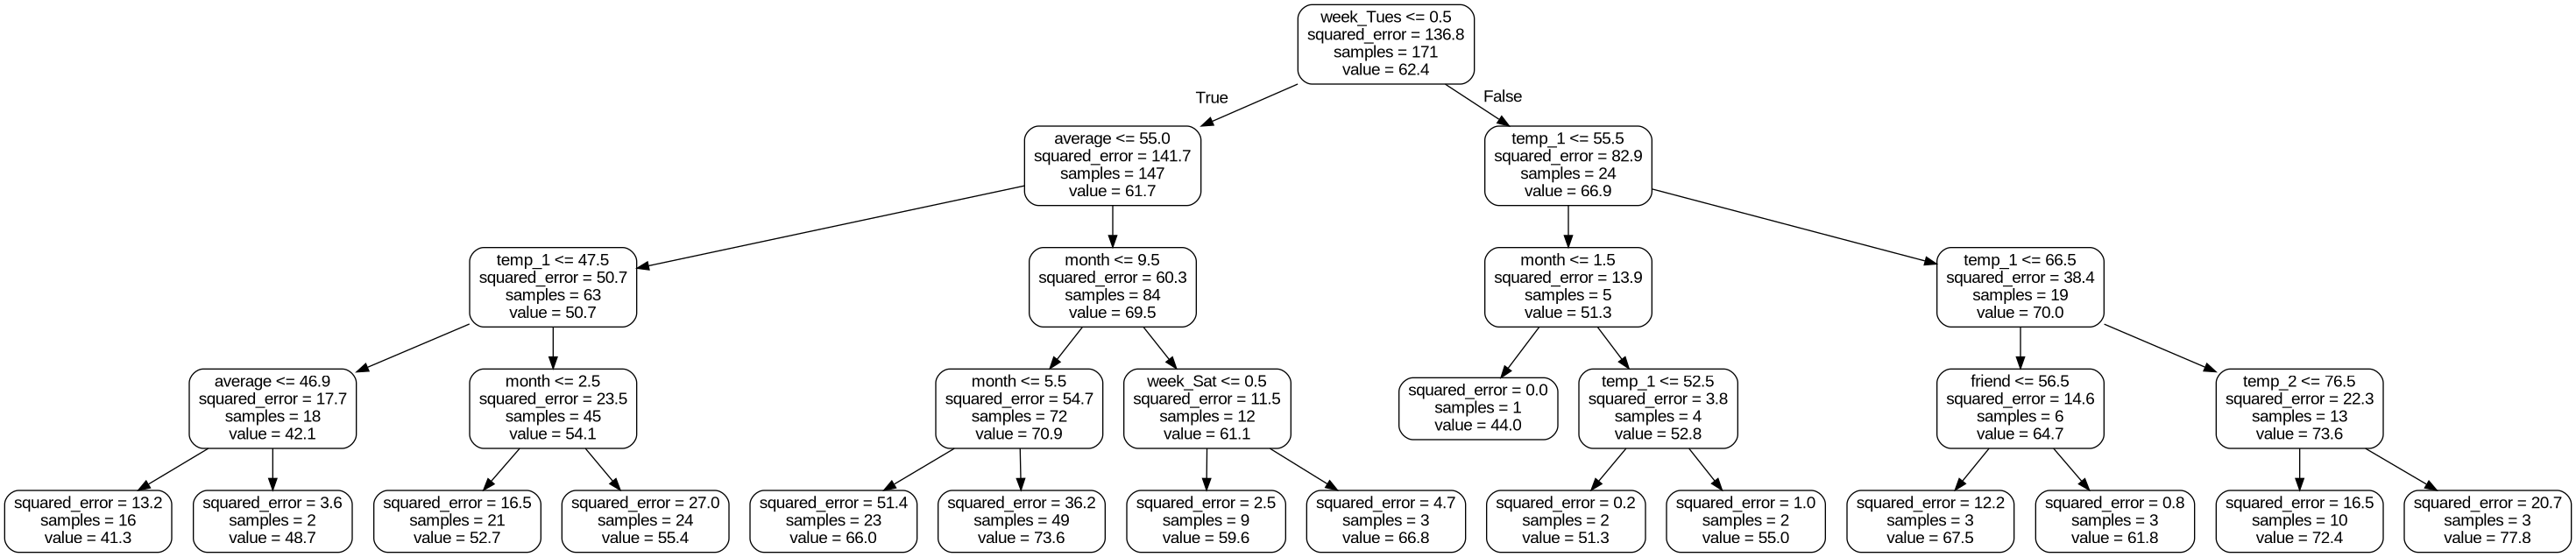

In [38]:
# Pull out one tree from the forest
tree = rf.estimators_[998]

# Export the image to a dot file
export_graphviz(tree, out_file = 'RF_2.dot', feature_names = feature_list, rounded = True, precision = 1)

# Use dot file to create a graph
(graph, ) = pydot.graph_from_dot_file('RF_2.dot')

# Write graph to a png file
graph.write_png('RF_2.png');

# Display png file
Image(filename='RF_2.png')

In [39]:
print('The depth of this tree is:', tree.tree_.max_depth)

The depth of this tree is: 4


### Train new smaller random forest model

In [40]:
%%time

# Instantiate smaller random forest regressor.  Limit # trees to 10 and max tree depth to 4 levels.
rf_small = RandomForestRegressor(n_estimators=2000, max_features=5, max_depth=4, random_state=42)

# Train the smaller random forest
rf_small.fit(train_df, train_labels)

CPU times: user 2.73 s, sys: 11.7 ms, total: 2.75 s
Wall time: 2.76 s


RandomForestRegressor(max_depth=4, max_features=5, n_estimators=2000,
                      random_state=42)

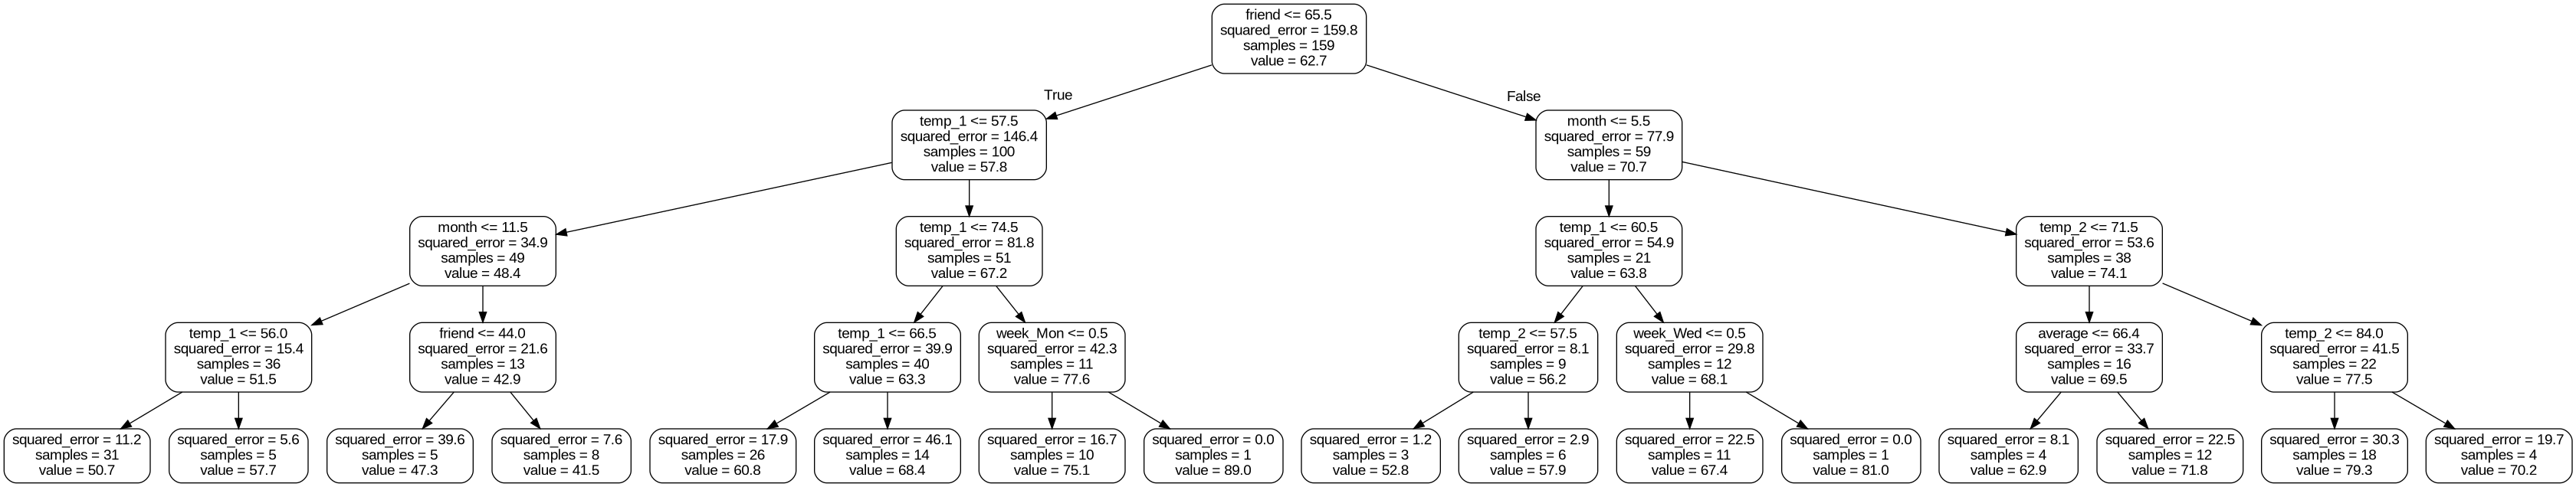

In [41]:
# Extract a small tree
tree_small = rf_small.estimators_[7]

# Save the tree as a png image
export_graphviz(tree_small, out_file = 'RF_2_small_2.dot', feature_names = feature_list, rounded = True, precision = 1)
(graph, ) = pydot.graph_from_dot_file('RF_2_small_2.dot')
graph.write_png('RF_2_small_2.png')

# Display png file
Image(filename='RF_2_small_2.png')

In [42]:
print('The depth of this tree is:', tree_small.tree_.max_depth)

The depth of this tree is: 4


In [43]:
# Use the forest's predict method on the test data
predictions = rf_small.predict(test_df)

# Calculate the absolute errors
errors = abs(predictions - test_labels)

# Print average model error (mean absolute error - mae)
print('Average (small) model error:', round(np.mean(errors), 3), 'degrees.')

# Compare to baseline
improvement_baseline = 100 * abs(np.mean(errors) - np.mean(baseline_errors)) / np.mean(baseline_errors)
print('(Small model) improvement over baseline:', round(improvement_baseline, 2), '%.')

# Calculate mean absolute percentage error (MAPE)
mape = 100 * (errors / test_labels)

# Calculate and display accuracy
accuracy = 100 - np.mean(mape)
print('(Small model) accuracy:', round(accuracy, 2), '%.')

Average (small) model error: 3.682 degrees.
(Small model) improvement over baseline: 27.23 %.
(Small model) accuracy: 94.24 %.


### Train new random forest model with fewer features but same hyperparameters (# of trees, max tree depth) as original model

In [44]:
# Get numerical feature importances
importances = list(rf.feature_importances_)

# List of tuples with variable and importance
feature_importances = [(feature, round(importance, 2)) for feature, importance in zip(feature_list, importances)]

# Sort the feature importances by most important first
feature_importances = sorted(feature_importances, key = lambda x: x[1], reverse = True)

# Print out the feature and importances
[print('Variable: {:10} Importance: {}'.format(*pair)) for pair in feature_importances];

Variable: temp_1     Importance: 0.4
Variable: average    Importance: 0.3
Variable: temp_2     Importance: 0.17
Variable: month      Importance: 0.06
Variable: friend     Importance: 0.05
Variable: day        Importance: 0.01
Variable: year       Importance: 0.0
Variable: week_Fri   Importance: 0.0
Variable: week_Mon   Importance: 0.0
Variable: week_Sat   Importance: 0.0
Variable: week_Sun   Importance: 0.0
Variable: week_Thurs Importance: 0.0
Variable: week_Tues  Importance: 0.0
Variable: week_Wed   Importance: 0.0


In [45]:
feature_importances

[('temp_1', np.float64(0.4)),
 ('average', np.float64(0.3)),
 ('temp_2', np.float64(0.17)),
 ('month', np.float64(0.06)),
 ('friend', np.float64(0.05)),
 ('day', np.float64(0.01)),
 ('year', np.float64(0.0)),
 ('week_Fri', np.float64(0.0)),
 ('week_Mon', np.float64(0.0)),
 ('week_Sat', np.float64(0.0)),
 ('week_Sun', np.float64(0.0)),
 ('week_Thurs', np.float64(0.0)),
 ('week_Tues', np.float64(0.0)),
 ('week_Wed', np.float64(0.0))]

In [46]:
feature_list

['year',
 'month',
 'day',
 'temp_2',
 'temp_1',
 'average',
 'friend',
 'week_Fri',
 'week_Mon',
 'week_Sat',
 'week_Sun',
 'week_Thurs',
 'week_Tues',
 'week_Wed']

In [47]:
importances

[np.float64(0.0),
 np.float64(0.05699145914528372),
 np.float64(0.010849542328723791),
 np.float64(0.17209816363073238),
 np.float64(0.4013131975541571),
 np.float64(0.3023992299508212),
 np.float64(0.048495012478436024),
 np.float64(0.001828303192176522),
 np.float64(0.0012489040823732902),
 np.float64(0.0014250182596999058),
 np.float64(0.0011862620115710239),
 np.float64(0.00045183312674414264),
 np.float64(0.0009615806547058454),
 np.float64(0.0007514935845751215)]

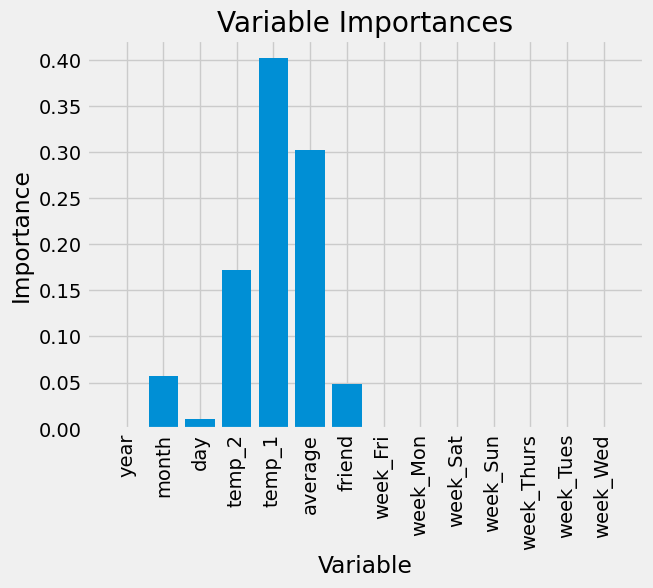

In [48]:
# Set the style
plt.style.use('fivethirtyeight')

# list of x locations for plotting
x_values = list(range(len(importances)))

# Make a bar chart
plt.bar(x_values, importances, orientation = 'vertical')

# Tick labels for x axis
plt.xticks(x_values, feature_list, rotation='vertical')

# Axis labels and title
plt.ylabel('Importance'); plt.xlabel('Variable'); plt.title('Variable Importances');

In [49]:
# Extract the two most important features
important_indices = [feature_list.index('temp_1'), feature_list.index('average')]
train_important = train_df[:, important_indices]
test_important = test_df[:, important_indices]

In [50]:
%%time

# Instantiate random forest regressor.  n = # of trees in the forest
rf_most_important = RandomForestRegressor(n_estimators=1000, random_state=42)

# Train the random forest with only the two most important variables
rf_most_important.fit(train_important, train_labels)

CPU times: user 2.4 s, sys: 16.8 ms, total: 2.41 s
Wall time: 2.49 s


RandomForestRegressor(n_estimators=1000, random_state=42)

In [51]:
# Make predictions and determine the error
predictions = rf_most_important.predict(test_important)

# Calculate the absolute errors
errors = abs(predictions - test_labels)

# Display the performance metrics
print('Average (important features only) model error:', round(np.mean(errors), 3), 'degrees.')

# Compare to baseline
improvement_baseline = 100 * abs(np.mean(errors) - np.mean(baseline_errors)) / np.mean(baseline_errors)
print('(Important features only) improvement over baseline:', round(improvement_baseline, 2), '%.')

# Calculate mean absolute percentage error (MAPE)
mape = 100 * (errors / test_labels)

# Calculate and display accuracy
accuracy = 100 - np.mean(mape)
print('(Important features only) accuracy:', round(accuracy, 2), '%.')

Average (important features only) model error: 3.918 degrees.
(Important features only) improvement over baseline: 22.57 %.
(Important features only) accuracy: 93.77 %.


# SVM 1

### Import libraries

In [52]:
import pprint as pp
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

### Load data

Dataset: UCI Skin Segmentation Data Set: http://archive.ics.uci.edu/ml/datasets/Skin+Segmentation#

The skin dataset is collected by randomly sampling B,G,R values from face images of various age groups (young, middle, and old), race groups (white, black, and asian), and genders obtained from FERET database and PAL database.  
Total learning sample size is 245057; out of which 50859 is the skin samples and 194198 is non-skin samples.

Color FERET Image Database: [Web Link], PAL Face Database from Productive Aging Laboratory, The University of Texas at Dallas: [Web Link].

In [53]:
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/Skin_NonSkin.txt',
                 header=None, names=['B', 'G', 'R', 'Skin'], sep='\t')

### Examine data

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 245057 entries, 0 to 245056
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   B       245057 non-null  int64
 1   G       245057 non-null  int64
 2   R       245057 non-null  int64
 3   Skin    245057 non-null  int64
dtypes: int64(4)
memory usage: 7.5 MB


In [55]:
df.shape

(245057, 4)

In [56]:
df=df.sample(n=1000)

In [57]:
# Review distribution of target values
#  1=skin, 2=non-skin
df['Skin'].value_counts()

,count
Skin,
2,791
1,209


#### 1 is skin while 2 is non-skin

### Separate independent and dependent variables

In [58]:
X = df.drop('Skin', axis=1)     # Independent variables
y = df['Skin']                  # Dependent variable

### Scale the features
Since SVM is very sensitive to features with different ranges, we need to scale the features  
Standardize the feature values around 0 with a standard deviation of 1

In [59]:
# Instantiate StandardScaler
sc = StandardScaler()

In [60]:
X = sc.fit_transform(X)

### Split data into training and test sets

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Train model with default hyperparameters

In [62]:
# Instantiate SVC classifier with default radial basis function (rbf) kernel
classifier = SVC()

In [63]:
pp.pprint(classifier.get_params())

{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'probability': False,
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}


In [64]:
%%time

# Fit the model
classifier.fit(X_train, y_train)

CPU times: user 6.41 ms, sys: 20 µs, total: 6.43 ms
Wall time: 7.43 ms


SVC()

### Evaluate model

In [65]:
%%time

model_preds = classifier.predict(X_test)
model_accuracy = accuracy_score(y_test, model_preds)
print(f"SVC (with default RBF kernel) score: {round((model_accuracy * 100), 3)}%")

SVC (with default RBF kernel) score: 98.0%
CPU times: user 4.24 ms, sys: 0 ns, total: 4.24 ms
Wall time: 4.27 ms


### Train model with the linear kernel

In [66]:
# Instantiate SVC classifier with the linear kernel
classifier = SVC(kernel='linear')

In [67]:
%%time

# Fit the model
classifier.fit(X_train, y_train)

CPU times: user 8.73 ms, sys: 915 µs, total: 9.65 ms
Wall time: 12.3 ms


SVC(kernel='linear')

### Evaluate updated model

In [68]:
%%time

model_preds = classifier.predict(X_test)
model_accuracy = accuracy_score(y_test, model_preds)
print(f"SVC (with linear kernel) score: {round((model_accuracy * 100), 3)}%")

SVC (with linear kernel) score: 91.667%
CPU times: user 3.62 ms, sys: 0 ns, total: 3.62 ms
Wall time: 4.24 ms


### Train model with the polynomial kernel

In [69]:
# Instantiate SVC classifier with the polynomial (poly) kernel
classifier = SVC(kernel='poly')

In [70]:
%%time

# Fit the model
classifier.fit(X_train, y_train)

CPU times: user 13 ms, sys: 50 µs, total: 13.1 ms
Wall time: 17.1 ms


SVC(kernel='poly')

### Evaluate updated model

In [71]:
%%time

model_preds = classifier.predict(X_test)
model_accuracy = accuracy_score(y_test, model_preds)
print(f"SVC (with polynomial kernel) score: {round((model_accuracy * 100), 3)}%")

SVC (with polynomial kernel) score: 93.0%
CPU times: user 4.2 ms, sys: 13 µs, total: 4.21 ms
Wall time: 3.9 ms
